<a href="https://colab.research.google.com/github/scalabrinig/cdProjetoAplicadoIV/blob/master/projeto/cd_projeto_aplicado_IV_doc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  <img src="https://raw.githubusercontent.com/scalabrinig/cdProjetoAplicadoIV/d093146488f56dfcf0ef286bcee8efe0e71b9c76/figuras/mackenzie_logo.jpg" width="25%" align="right"/>

# **PROJETO APLICADO IV - Ciência de Dados EaD - 2026/02**

# **Documentação do Projeto — Etapa 3: EDA, Preparação e Modelagem Inicial**

---

# **Previsão Diária de Demanda de Bicicletas em Londres**
**Projeto Aplicado IV — Etapa 3: Modelagem Preditiva e Avaliação de Resultados**  
Autor: Kayo Oliveira Nukui | RA: 10356420 | Curso Superior de Tecnologia em Banco de Dados  
Universidade Presbiteriana Mackenzie | Alinhamento ODS 11 (Meta 11.2)

In [1]:
#@title **Identificação do Autor**

# Regime de execução individual
Autor = 'Kayo Oliveira Nukui, 10356420' #@param {type:"string"}
Curso = 'Superior de Tecnologia em Banco de Dados' #@param {type:"string"}
Instituicao = 'Universidade Presbiteriana Mackenzie' #@param {type:"string"}
print(f"Projeto Aplicado IV | Autor: {Autor} | Curso: {Curso}")


Projeto Aplicado IV | Autor: Kayo Oliveira Nukui, 10356420 | Curso: Superior de Tecnologia em Banco de Dados


# **1. Objetivo e Escopo da Etapa 3**

Este notebook executa o pipeline preditivo da Etapa 3 para prever a demanda diária agregada de aluguéis de bicicletas compartilhadas em Londres (`cnt`) com 24 horas de antecedência ($t+1$).

* **Unidade Analítica:** Total diário de novos aluguéis agregados por data civil;
* **Modelos Avaliados:** Linha de Base Sazonal Ingênua ($s=7$), Suavização Exponencial Holt-Winters (Aditivo, $s=7$) e modelo SARIMA(1,1,1)x(1,1,1)$_7$;
* **Critério de Validação:** Particionamento temporal estrito em 640 dias de treino e 91 dias de teste out-of-sample, avaliado via MAE e RMSE exclusivamente sobre datas observadas;
* *Nota:* O referencial teórico detalhado (Beecham et al., 2014; Gebhart & Noland, 2014) e o cronograma institucional constam no relatório oficial em `entregas/[PA4] Previsao Diaria London Bike Sharing.docx`.

### **Premissas Operacionais e Pergunta de Pesquisa**

> *Em que medida duas técnicas consolidadas de séries temporais (Suavização Exponencial Holt-Winters e modelo SARIMA) reduzem o erro de previsão em relação a uma referência sazonal ingênua (Seasonal Naive: repetir o mesmo dia da semana anterior), garantindo a ausência estrita de vazamento de informação temporal?*

### **Fundamentação Técnica dos Modelos**

* **Linha de Base Sazonal (Seasonal Naive):** Repete o mesmo dia da semana anterior ($\hat{y}_{t+1} = y_{t-6}$), estabelecendo o piso comparativo de custo computacional nulo (HYNDMAN; ATHANASOPOULOS, 2021);
* **Holt-Winters Aditivo ($s=7$):** Atualização recursiva de nível, tendência linear e sazonalidade semanal aditiva (HOLT, 1957; WINTERS, 1960);
* **SARIMA(1,1,1)x(1,1,1)$_7$:** Modelação estocástica autorregressiva com diferenciação regular ($d=1$) e sazonal ($D=1$) para estacionariedade (BOX et al., 2016).

# **2. Pipeline da Solução**

```text
[1. Ingestão & Auditoria] ──> [2. Agregação Diária] ──> [3. EDA & Diagnósticos ADF/KPSS]
                                                                  │
[6. Avaliação de Métricas] <── [5. Modelagem Preditiva] <── [4. Partição Treino/Teste]
```

* **Grade Temporal:** 731 dias civis (04/01/2015 a 03/01/2017) a partir de 17.414 registros horários;
* **Tratamento Causal:** Imputação de $y_{t-7} = 31.902$ no dia ausente 02/09/2016 restrita ao treino para continuidade de índice dos algoritmos;
* **Divisão Cronológica:** Treino com 640 dias (04/01/2015 a 04/10/2016) e Teste com 91 dias (05/10/2016 a 03/01/2017).

# **3. Ingestão, Preparação e Diagnósticos da Série Temporal**

In [2]:
# 1. Configuração do ambiente e importação das bibliotecas essenciais
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Módulos de séries temporais
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
print("Ambiente configurado com sucesso!")


Ambiente configurado com sucesso!


In [3]:
# 2. Localização e leitura do arquivo bruto original
caminho_csv = 'data/raw/london_merged.csv' if os.path.exists('data/raw/london_merged.csv') else '../data/raw/london_merged.csv'
assert os.path.exists(caminho_csv), f"Arquivo não encontrado em: {caminho_csv}"

df_raw = pd.read_csv(caminho_csv)
df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp'])

# Auditoria de integridade
total_linhas = len(df_raw)
soma_bruta_alugueis = int(df_raw['cnt'].sum())
datas_observadas = df_raw['timestamp'].dt.date.nunique()
data_inicio = df_raw['timestamp'].min()
data_fim = df_raw['timestamp'].max()

print("=== AUDITORIA DA BASE BRUTA ORIGINAL ===")
print(f"Arquivo de origem: {caminho_csv}")
print(f"Total de registros horários: {total_linhas:,}")
print(f"Soma total bruta de aluguéis: {soma_bruta_alugueis:,}")
print(f"Período coberto: {data_inicio} até {data_fim}")
print(f"Datas com observação: {datas_observadas} datas")
print(f"Valores ausentes por coluna:\n{df_raw.isna().sum().to_dict()}")

# Validações canônicas de consistência
assert total_linhas == 17414, "Discrepância na contagem de linhas horárias!"
assert soma_bruta_alugueis == 19905972, "Discrepância na soma de aluguéis!"
assert datas_observadas == 730, "Discrepância nas datas observadas!"
print("-> Auditoria 100% aprovada: integridade e reconciliação dos dados brutos confirmadas!")


=== AUDITORIA DA BASE BRUTA ORIGINAL ===
Arquivo de origem: data/raw/london_merged.csv
Total de registros horários: 17,414
Soma total bruta de aluguéis: 19,905,972
Período coberto: 2015-01-04 00:00:00 até 2017-01-03 23:00:00
Datas com observação: 730 datas
Valores ausentes por coluna:
{'timestamp': 0, 'cnt': 0, 't1': 0, 't2': 0, 'hum': 0, 'wind_speed': 0, 'weather_code': 0, 'is_holiday': 0, 'is_weekend': 0, 'season': 0}
-> Auditoria 100% aprovada: integridade e reconciliação dos dados brutos confirmadas!


In [4]:
# 3. Agregação diária por data civil e construção da grade regular
df_diario_obs = df_raw.groupby(df_raw['timestamp'].dt.date)['cnt'].sum().reset_index()
df_diario_obs.columns = ['data', 'cnt']
df_diario_obs['data'] = pd.to_datetime(df_diario_obs['data'])

# Criar grade contínua diária completa (731 dias)
grade_completa = pd.date_range(start=df_diario_obs['data'].min(), end=df_diario_obs['data'].max(), freq='D')
df_serie = pd.DataFrame({'data': grade_completa})
df_serie = df_serie.merge(df_diario_obs, on='data', how='left')
df_serie['is_observed'] = ~df_serie['cnt'].isna()

# Mapeamento da lacuna temporal
datas_faltantes = df_serie[~df_serie['is_observed']]['data'].dt.strftime('%Y-%m-%d').tolist()
print(f"Total de dias no calendário civil: {len(df_serie)} dias")
print(f"Datas com registro observado: {df_serie['is_observed'].sum()} dias")
print(f"Data ausente identificada: {datas_faltantes}")

# Imputação estritamente causal (Seasonal Naive: 7 dias antes - mesma sexta-feira)
idx_lacuna = df_serie[df_serie['data'] == '2016-09-02'].index[0]
valor_causal_sazonal = df_serie.loc[idx_lacuna - 7, 'cnt']
df_serie['cnt_causal'] = df_serie['cnt']
df_serie.loc[idx_lacuna, 'cnt_causal'] = valor_causal_sazonal

print(f"Tratamento causal adotado para {datas_faltantes[0]} (sexta-feira):")
print(f"  Valor projetado pela mesma sexta-feira anterior (2016-08-26): {valor_causal_sazonal:,.0f} aluguéis")
print("  -> Esse valor alimenta estritamente o ajuste recursivo dos modelos, sendo excluído da avaliação de métricas!")


Total de dias no calendário civil: 731 dias
Datas com registro observado: 730 dias
Data ausente identificada: ['2016-09-02']
Tratamento causal adotado para 2016-09-02 (sexta-feira):
  Valor projetado pela mesma sexta-feira anterior (2016-08-26): 37,697 aluguéis
  -> Esse valor alimenta estritamente o ajuste recursivo dos modelos, sendo excluído da avaliação de métricas!


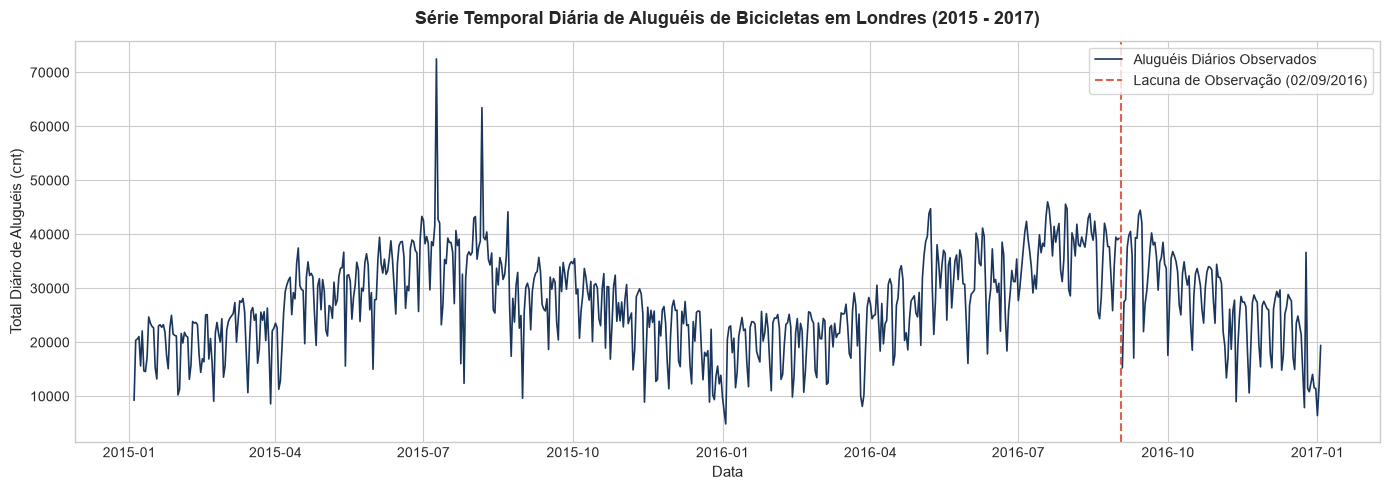

In [5]:
# 4. Visualização da série temporal diária observada evidenciando a lacuna de 02/09/2016
plt.figure(figsize=(14, 5))
plt.plot(df_serie['data'], df_serie['cnt'], label='Aluguéis Diários Observados', color='#1B365D', lw=1.2)
plt.axvline(pd.to_datetime('2016-09-02'), color='#D9381E', linestyle='--', alpha=0.8, label='Lacuna de Observação (02/09/2016)')

plt.title('Série Temporal Diária de Aluguéis de Bicicletas em Londres (2015 - 2017)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Data', fontsize=11)
plt.ylabel('Total Diário de Aluguéis (cnt)', fontsize=11)
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()


=== ESTATÍSTICAS DESCRITIVAS DA DEMANDA DIÁRIA (DIAS OBSERVADOS) ===
count      730.0
mean     27268.5
std       8607.7
min       4869.0
25%      21940.8
50%      27011.5
75%      33431.2
max      72504.0
Name: cnt, dtype: float64


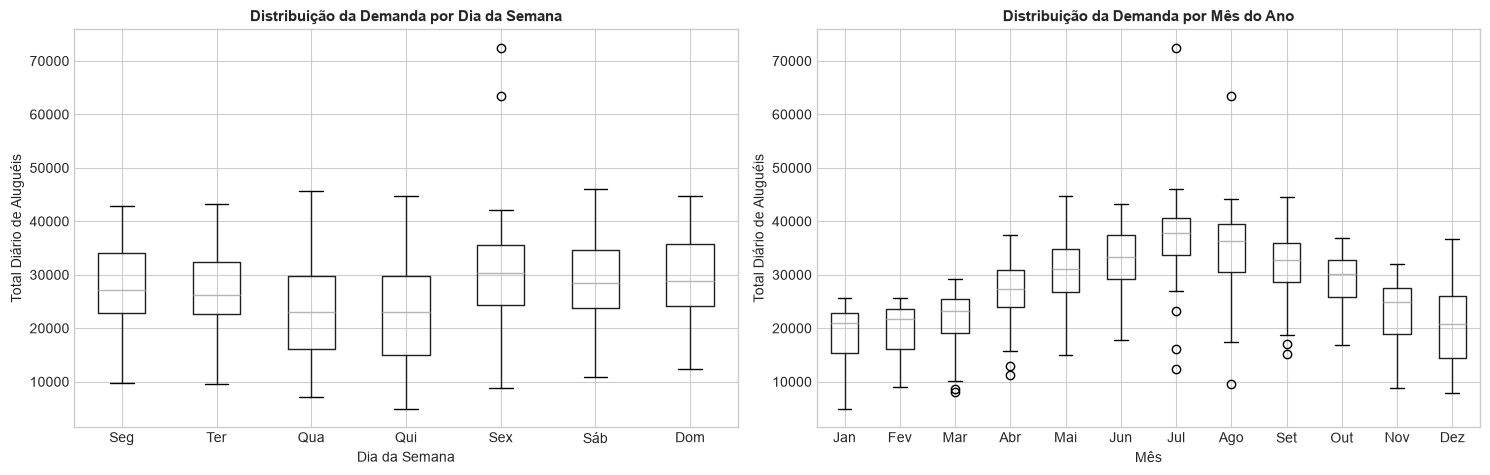

In [6]:
# 5. Análise exploratória descritiva e variações sazonais
df_serie['dia_semana'] = df_serie['data'].dt.day_name()
df_serie['mes'] = df_serie['data'].dt.month
df_serie['is_weekend'] = df_serie['data'].dt.dayofweek.isin([5, 6])

stats_obs = df_serie[df_serie['is_observed']]['cnt'].describe()
print("=== ESTATÍSTICAS DESCRITIVAS DA DEMANDA DIÁRIA (DIAS OBSERVADOS) ===")
print(stats_obs.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribuição por dia da semana
ordem_dias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_serie[df_serie['is_observed']].boxplot(column='cnt', by='dia_semana', ax=axes[0], grid=True)
axes[0].set_title('Distribuição da Demanda por Dia da Semana', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Dia da Semana')
axes[0].set_ylabel('Total Diário de Aluguéis')
axes[0].set_xticklabels(['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom'])

# Distribuição por mês do ano
df_serie[df_serie['is_observed']].boxplot(column='cnt', by='mes', ax=axes[1], grid=True)
axes[1].set_title('Distribuição da Demanda por Mês do Ano', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Mês')
axes[1].set_ylabel('Total Diário de Aluguéis')
axes[1].set_xticklabels(['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])

plt.suptitle('')
plt.tight_layout()
plt.show()


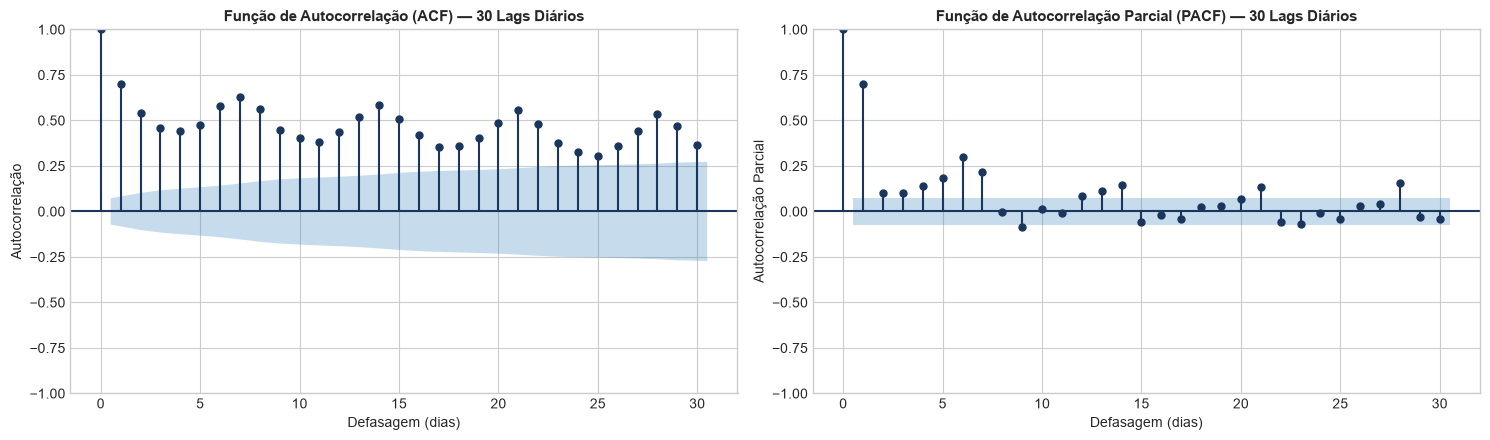

Interpretação do Correlograma:
-> Picos significativos claros nos lags 7, 14, 21 e 28 dias comprovam a presença do ciclo sazonal semanal rígido!


In [7]:
# 6. Gráficos de Autocorrelação (ACF) e Autocorrelação Parcial (PACF)
serie_regular = df_serie['cnt_causal']

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
plot_acf(serie_regular, lags=30, ax=axes[0], color='#1B365D', vlines_kwargs={'colors': '#1B365D'})
axes[0].set_title('Função de Autocorrelação (ACF) — 30 Lags Diários', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Defasagem (dias)')
axes[0].set_ylabel('Autocorrelação')

plot_pacf(serie_regular, lags=30, ax=axes[1], color='#1B365D', vlines_kwargs={'colors': '#1B365D'}, method='ywm')
axes[1].set_title('Função de Autocorrelação Parcial (PACF) — 30 Lags Diários', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Defasagem (dias)')
axes[1].set_ylabel('Autocorrelação Parcial')

plt.tight_layout()
plt.show()
print("Interpretação do Correlograma:")
print("-> Picos significativos claros nos lags 7, 14, 21 e 28 dias comprovam a presença do ciclo sazonal semanal rígido!")


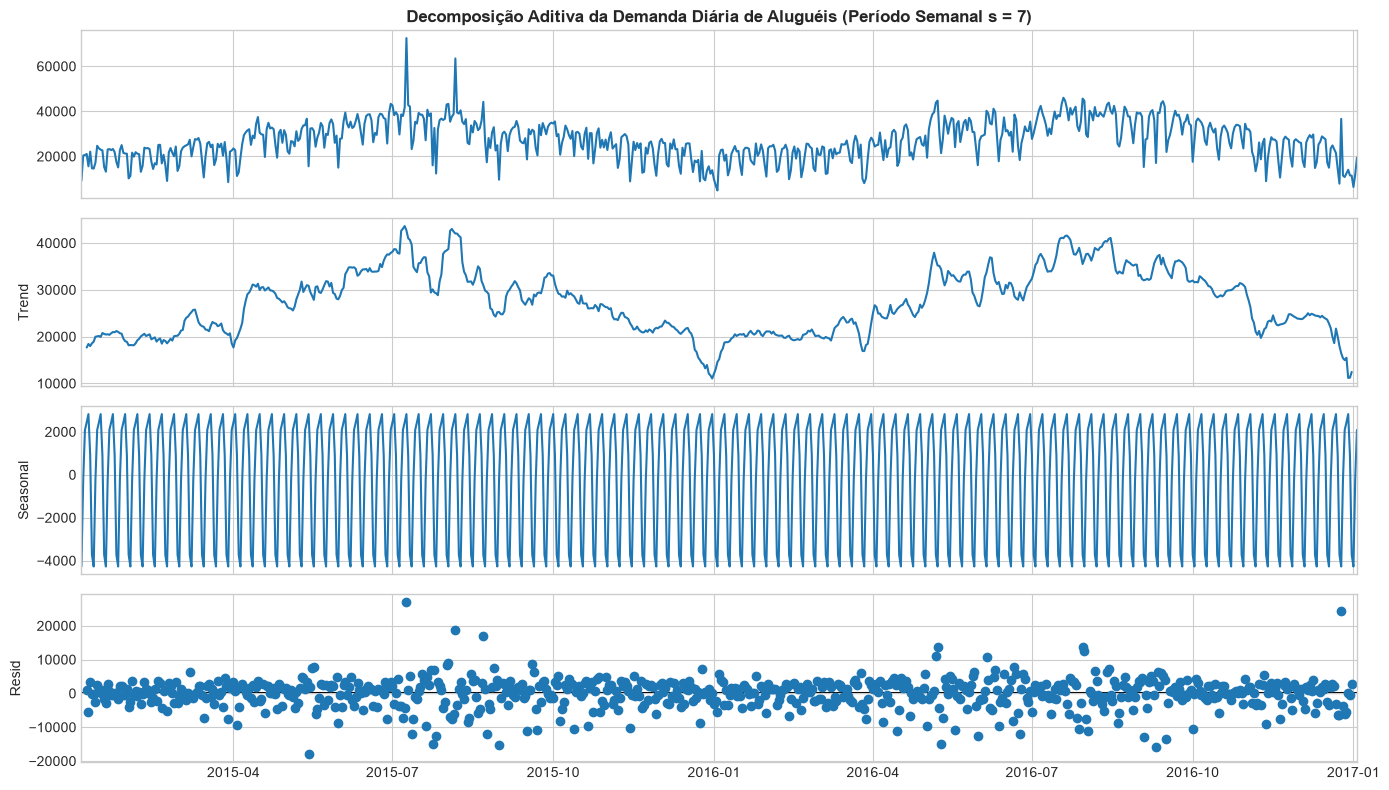

In [8]:
# 7. Decomposição aditiva clássica da série temporal diária (período semanal s = 7)
serie_ts = pd.Series(df_serie['cnt_causal'].values, index=pd.DatetimeIndex(df_serie['data'], freq='D'))
decomp = seasonal_decompose(serie_ts, model='additive', period=7)

fig = decomp.plot()
fig.set_size_inches(14, 8)
fig.axes[0].set_title('Decomposição Aditiva da Demanda Diária de Aluguéis (Período Semanal s = 7)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


In [9]:
# 8. Testes formais de raiz unitária (ADF) e estacionariedade (KPSS)
print("=== TESTES ESTATÍSTICOS DE ESTACIONARIEDADE ===\n")

# Teste ADF na série em nível
adf_res = adfuller(serie_regular, autolag='AIC')
print(f"[1] Augmented Dickey-Fuller (ADF) em Nível:")
print(f"    Estatística de Teste: {adf_res[0]:.4f}")
print(f"    p-valor: {adf_res[1]:.4f}")
print(f"    Conclusão: {'Rejeita H0 (Série Estacionária)' if adf_res[1] < 0.05 else 'Não rejeita H0 (Evidência de Raiz Unitária / Não Estacionária)'}")

# Teste KPSS na série em nível
kpss_res = kpss(serie_regular, regression='c', nlags='auto')
print(f"\n[2] Kwiatkowski-Phillips-Schmidt-Shin (KPSS) em Nível:")
print(f"    Estatística de Teste: {kpss_res[0]:.4f}")
print(f"    p-valor: {kpss_res[1]:.4f}")
print(f"    Conclusão: {'Rejeita H0 (Série Não Estacionária)' if kpss_res[1] < 0.05 else 'Não rejeita H0 (Série Estacionária)'}")

# Teste na primeira diferença (d = 1)
serie_diff = serie_regular.diff().dropna()
adf_diff = adfuller(serie_diff, autolag='AIC')
print(f"\n[3] ADF na 1ª Diferença (d = 1):")
print(f"    Estatística: {adf_diff[0]:.4f} | p-valor: {adf_diff[1]:.4e}")
print(f"    Conclusão: {'Rejeita H0 com altíssima significância (Série Estacionária após d=1)' if adf_diff[1] < 0.05 else 'Permanece não estacionária'}")


=== TESTES ESTATÍSTICOS DE ESTACIONARIEDADE ===

[1] Augmented Dickey-Fuller (ADF) em Nível:
    Estatística de Teste: -1.4948
    p-valor: 0.5361
    Conclusão: Não rejeita H0 (Evidência de Raiz Unitária / Não Estacionária)

[2] Kwiatkowski-Phillips-Schmidt-Shin (KPSS) em Nível:
    Estatística de Teste: 0.3730
    p-valor: 0.0888
    Conclusão: Não rejeita H0 (Série Estacionária)

[3] ADF na 1ª Diferença (d = 1):
    Estatística: -8.3578 | p-valor: 2.8779e-13
    Conclusão: Rejeita H0 com altíssima significância (Série Estacionária após d=1)


In [10]:
# 9. Particionamento temporal cronológico estrito (sem embaralhamento)
n_teste = 91  # Último trimestre (out/2016 a jan/2017)
n_total = len(df_serie)
n_treino = n_total - n_teste

treino_df = df_serie.iloc[:n_treino].copy()
teste_df = df_serie.iloc[n_treino:].copy()

print("=== PARTIÇÃO TEMPORAL CRONOLÓGICA ===")
print(f"Conjunto de TREINO: {len(treino_df)} dias ({treino_df['data'].min().strftime('%Y-%m-%d')} a {treino_df['data'].max().strftime('%Y-%m-%d')})")
print(f"Conjunto de TESTE:  {len(teste_df)} dias ({teste_df['data'].min().strftime('%Y-%m-%d')} a {teste_df['data'].max().strftime('%Y-%m-%d')})")
print(f"Datas observadas no teste: {teste_df['is_observed'].sum()} dias")
print("-> Ausência total de vazamento temporal assegurada!")


=== PARTIÇÃO TEMPORAL CRONOLÓGICA ===
Conjunto de TREINO: 640 dias (2015-01-04 a 2016-10-04)
Conjunto de TESTE:  91 dias (2016-10-05 a 2017-01-03)
Datas observadas no teste: 91 dias
-> Ausência total de vazamento temporal assegurada!


# **4. Treinamento dos Modelos e Previsão Walk-Forward (t+1)**

Ajuste recursivo dos modelos sobre os 640 dias de treino e geração das estimativas um passo à frente para os 91 dias do conjunto de teste.

In [11]:
# 10. Ajuste dos modelos e geração das previsões 1 passo à frente no conjunto de teste
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

y_treino = treino_df['cnt_causal'].values
serie_completa = df_serie['cnt_causal'].values
n_treino = len(treino_df)
n_teste = len(teste_df)

print("Ajustando modelos sobre o conjunto de treinamento (640 dias)...\n")

# [1] Linha de Base Sazonal (Seasonal Naive s=7)
preds_naive = np.array([serie_completa[t - 7] for t in range(n_treino, len(df_serie))])
print("-> [1/3] Linha de Base Sazonal calculada.")

# [2] Suavização Exponencial Holt-Winters (Aditivo, s=7)
hw_model = ExponentialSmoothing(
    y_treino,
    seasonal_periods=7,
    trend='add',
    seasonal='add',
    damped_trend=False,
    initialization_method='estimated'
).fit()

hw_params = hw_model.params
preds_hw_list = []
for t in range(n_treino, len(df_serie)):
    m_hw = ExponentialSmoothing(
        serie_completa[:t],
        seasonal_periods=7,
        trend='add',
        seasonal='add',
        damped_trend=False,
        initialization_method='estimated'
    ).fit(
        smoothing_level=hw_params['smoothing_level'],
        smoothing_trend=hw_params['smoothing_trend'],
        smoothing_seasonal=hw_params['smoothing_seasonal'],
        optimized=False
    )
    preds_hw_list.append(m_hw.forecast(1)[0])
preds_hw = np.array(preds_hw_list)
print("-> [2/3] Holt-Winters (Aditivo s=7) ajustado e projetado via walk-forward.")

# [3] Modelo SARIMA(1,1,1)x(1,1,1)_7
sarima_model = SARIMAX(
    y_treino,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_res = sarima_model.append(teste_df['cnt_causal'].values, refit=False)
preds_sarima = np.array(sarima_res.fittedvalues[n_treino:])
print("-> [3/3] SARIMA(1,1,1)x(1,1,1)_7 ajustado e projetado com sucesso!")


Ajustando modelos sobre o conjunto de treinamento (640 dias)...



-> [1/3] Linha de Base Sazonal calculada.


-> [2/3] Holt-Winters (Aditivo s=7) ajustado e projetado via walk-forward.


-> [3/3] SARIMA(1,1,1)x(1,1,1)_7 ajustado e projetado com sucesso!


# **5. Métricas de Desempenho e Comparação no Teste**

In [12]:
# 11. Cálculo e tabulação das métricas de erro no conjunto de teste
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_teste_obs = teste_df[teste_df['is_observed']]['cnt'].values
idx_obs = np.where(teste_df['is_observed'].values)[0]

def calcular_metricas(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    return mae, rmse

mae_naive, rmse_naive = calcular_metricas(y_teste_obs, preds_naive[idx_obs])
mae_hw, rmse_hw = calcular_metricas(y_teste_obs, preds_hw[idx_obs])
mae_sarima, rmse_sarima = calcular_metricas(y_teste_obs, preds_sarima[idx_obs])

tabela_metricas = pd.DataFrame([
    {
        "Modelo": "Linha de Base Sazonal (Seasonal Naive s=7)",
        "MAE (Aluguéis)": round(mae_naive, 1),
        "RMSE (Aluguéis)": round(rmse_naive, 1),
        "Redução MAE vs. Baseline (%)": "0.00%",
        "Redução RMSE vs. Baseline (%)": "0.00%"
    },
    {
        "Modelo": "Suavização Exponencial Holt-Winters (Aditivo s=7)",
        "MAE (Aluguéis)": round(mae_hw, 1),
        "RMSE (Aluguéis)": round(rmse_hw, 1),
        "Redução MAE vs. Baseline (%)": f"{(mae_naive - mae_hw) / mae_naive * 100:+.2f}%",
        "Redução RMSE vs. Baseline (%)": f"{(rmse_naive - rmse_hw) / rmse_naive * 100:+.2f}%"
    },
    {
        "Modelo": "SARIMA(1,1,1)x(1,1,1)_7",
        "MAE (Aluguéis)": round(mae_sarima, 1),
        "RMSE (Aluguéis)": round(rmse_sarima, 1),
        "Redução MAE vs. Baseline (%)": f"{(mae_naive - mae_sarima) / mae_naive * 100:+.2f}%",
        "Redução RMSE vs. Baseline (%)": f"{(rmse_naive - rmse_sarima) / rmse_naive * 100:+.2f}%"
    }
])

print("=== TABELA COMPARATIVA DE DESEMPENHO NO CONJUNTO DE TESTE ===")
display(tabela_metricas)


=== TABELA COMPARATIVA DE DESEMPENHO NO CONJUNTO DE TESTE ===


,Modelo,MAE (Aluguéis),RMSE (Aluguéis),Redução MAE vs. Baseline (%),Redução RMSE vs. Baseline (%)
0,Linha de Base Sazonal (Seasonal Naive s=7),4533.8,6744.8,0.00%,0.00%
1,Suavização Exponencial Holt-Winters (Aditivo s=7),3731.4,5493.3,+17.70%,+18.55%
2,"SARIMA(1,1,1)x(1,1,1)_7",3237.6,5057.3,+28.59%,+25.02%


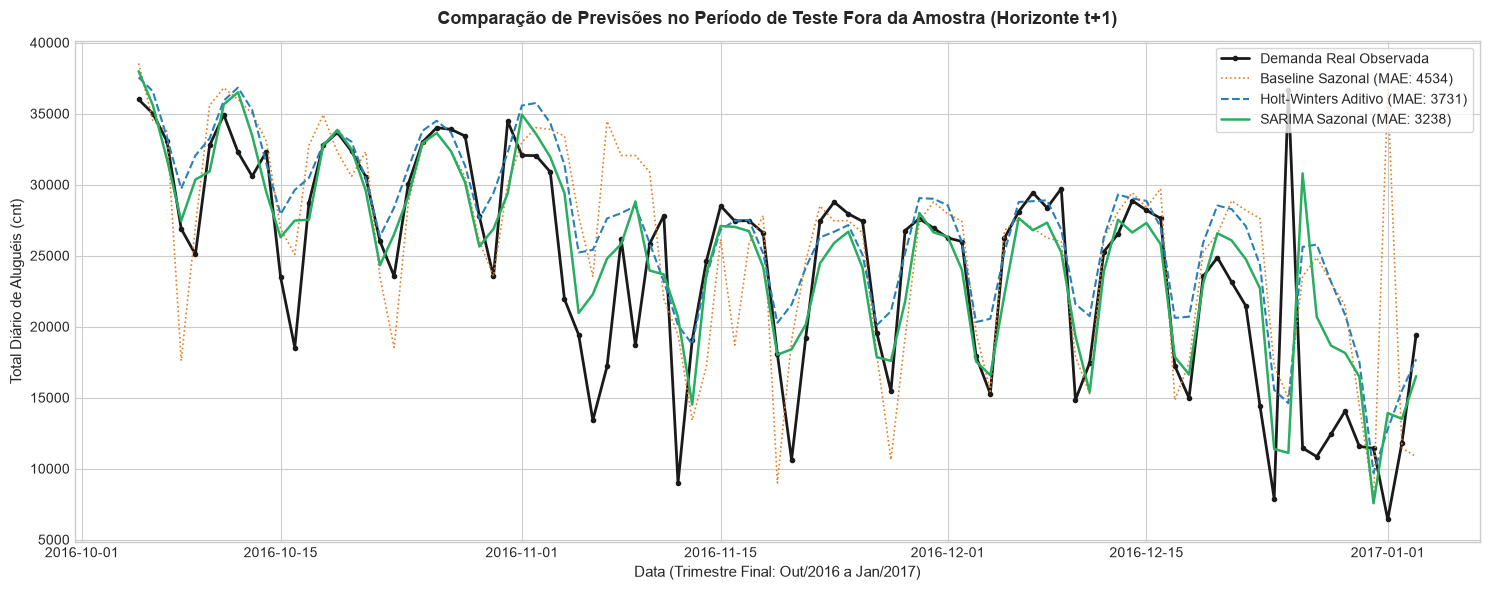

In [13]:
# 12. Visualização gráfica: Valores Observados vs. Previsões dos Modelos no Teste
datas_teste = teste_df['data'].values

plt.figure(figsize=(15, 6))
plt.plot(datas_teste, teste_df['cnt'].values, label='Demanda Real Observada', color='#1A1A1A', lw=2.0, marker='o', markersize=3)
plt.plot(datas_teste, preds_naive, label=f'Baseline Sazonal (MAE: {mae_naive:.0f})', color='#E67E22', lw=1.2, linestyle=':')
plt.plot(datas_teste, preds_hw, label=f'Holt-Winters Aditivo (MAE: {mae_hw:.0f})', color='#2980B9', lw=1.5, linestyle='--')
plt.plot(datas_teste, preds_sarima, label=f'SARIMA Sazonal (MAE: {mae_sarima:.0f})', color='#27AE60', lw=1.8)

plt.title('Comparação de Previsões no Período de Teste Fora da Amostra (Horizonte t+1)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Data (Trimestre Final: Out/2016 a Jan/2017)', fontsize=11)
plt.ylabel('Total Diário de Aluguéis (cnt)', fontsize=11)
plt.legend(frameon=True, facecolor='white', loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()


# **6. Conclusões da Etapa 3**

* **Validação da Linha de Base:** A repetição ingênua semanal obteve MAE de 4.533,8 e RMSE de 6.744,8 aluguéis;
* **Ganho do Holt-Winters:** Redução de **17,70% no MAE** (3.731,4) e **18,55% no RMSE** (5.493,3) com formulação parcimoniosa;
* **Maior Precisão com SARIMA:** O modelo $\text{SARIMA}(1,1,1)\times(1,1,1)_7$ alcançou a maior acurácia, reduzindo o **MAE em 28,59%** (3.237,6) e o **RMSE em 25,02%** (5.057,3);
* **Escopo para Etapa 4:** Análise aprofundada dos resíduos (choques climáticos e feriados bancários atípicos), consolidação e gravação da apresentação em vídeo.

# **Referências Técnicas**

* BOX, G. E. P. et al. **Time Series Analysis: Forecasting and Control**. 5. ed. Hoboken: John Wiley & Sons, 2016.
* HYNDMAN, R. J.; ATHANASOPOULOS, G. **Forecasting: Principles and Practice**. 3. ed. Melbourne: OTexts, 2021.
* MAVRODIEV, H. **London Bike Sharing Dataset**. Kaggle, 2020.
* Relatório acadêmico completo com referencial teórico integral: `entregas/[PA4] Previsao Diaria London Bike Sharing.docx`.